
# Dashboard Preparation and Final Project Audit

## Project
Dynamic and Explainable Credit Risk Early-Warning System with Portfolio Stress Testing

## Objective
Prepare compact, validated summary datasets for the final dashboard, conduct an end-to-end audit of the analytical pipeline, and consolidate the evidence required for the final MTP report.

## Dashboard components
1. Model performance and probability calibration
2. Monthly portfolio risk monitoring
3. Borrower-level warning classifications
4. Portfolio exposure and concentration
5. Stress-testing and expected-loss sensitivity

## Storage strategy
Only aggregated CSV files and selected figures will be exported. Existing modelling datasets and intermediate Parquet files will remain unchanged.


In [1]:
# ============================================================
# NOTEBOOK 08: PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import duckdb
import json
import os
import gc

PROJECT_DIR = Path(
    r"C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning"
)

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"

DYNAMIC_DIR = PROCESSED_DIR / "dynamic_risk"
CALIBRATION_DIR = DYNAMIC_DIR / "calibration"
PORTFOLIO_DIR = DYNAMIC_DIR / "portfolio"

FEATURE_DIR = (
    PROCESSED_DIR /
    "feature_engineering"
)

MODEL_DIR = PROJECT_DIR / "models"
FIGURES_DIR = PROJECT_DIR / "figures"

DASHBOARD_DIR = PROCESSED_DIR / "dashboard"
DASHBOARD_FIGURES_DIR = FIGURES_DIR / "dashboard"

DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
DASHBOARD_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Core analytical files
TEST_RISK_FILE = DYNAMIC_DIR / "test_dynamic_risk.parquet"
VALIDATION_RISK_FILE = DYNAMIC_DIR / "validation_dynamic_risk.parquet"

TRAJECTORY_FILE = (
    DYNAMIC_DIR /
    "borrower_monthly_risk_trajectories.parquet"
)

BORROWER_SUMMARY_FILE = (
    DYNAMIC_DIR /
    "borrower_risk_summary.parquet"
)

FINAL_FEATURE_FILE = (
    FEATURE_DIR /
    "fannie_2018Q1_final_modelling_features.parquet"
)

HGB_MODEL_FILE = MODEL_DIR / "hist_gradient_boosting_baseline.joblib"

CALIBRATOR_FILE = (
    CALIBRATION_DIR /
    "sigmoid_calibration_parameters.json"
)

EWS_REGISTER_FILE = DYNAMIC_DIR / "borrower_ews_register.parquet"

SNAPSHOT_DATE = "2025-09-01"

print("PROJECT EXISTS:", PROJECT_DIR.exists())
print("PROJECT PATH:", PROJECT_DIR)
print("DASHBOARD OUTPUT:", DASHBOARD_DIR)
print("PROJECT CONFIGURATION INITIALISED")

PROJECT EXISTS: True
PROJECT PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning
DASHBOARD OUTPUT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dashboard
PROJECT CONFIGURATION INITIALISED


In [2]:
# ============================================================
# NOTEBOOK 08: PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import duckdb
import json
import os
import gc

PROJECT_DIR = Path(
    r"C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning"
)

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"

DYNAMIC_DIR = PROCESSED_DIR / "dynamic_risk"
CALIBRATION_DIR = DYNAMIC_DIR / "calibration"
PORTFOLIO_DIR = DYNAMIC_DIR / "portfolio"

FEATURE_DIR = (
    PROCESSED_DIR /
    "feature_engineering"
)

MODEL_DIR = PROJECT_DIR / "models"
FIGURES_DIR = PROJECT_DIR / "figures"

DASHBOARD_DIR = PROCESSED_DIR / "dashboard"
DASHBOARD_FIGURES_DIR = FIGURES_DIR / "dashboard"

DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
DASHBOARD_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Core analytical files
TEST_RISK_FILE = DYNAMIC_DIR / "test_dynamic_risk.parquet"
VALIDATION_RISK_FILE = DYNAMIC_DIR / "validation_dynamic_risk.parquet"

TRAJECTORY_FILE = (
    DYNAMIC_DIR /
    "borrower_monthly_risk_trajectories.parquet"
)

BORROWER_SUMMARY_FILE = (
    DYNAMIC_DIR /
    "borrower_risk_summary.parquet"
)

FINAL_FEATURE_FILE = (
    FEATURE_DIR /
    "fannie_2018Q1_final_modelling_features.parquet"
)

HGB_MODEL_FILE = MODEL_DIR / "hist_gradient_boosting_baseline.joblib"

CALIBRATOR_FILE = (
    CALIBRATION_DIR /
    "sigmoid_calibration_parameters.json"
)

EWS_REGISTER_FILE = DYNAMIC_DIR / "borrower_ews_register.parquet"

SNAPSHOT_DATE = "2025-09-01"

print("PROJECT EXISTS:", PROJECT_DIR.exists())
print("PROJECT PATH:", PROJECT_DIR)
print("DASHBOARD OUTPUT:", DASHBOARD_DIR)
print("PROJECT CONFIGURATION INITIALISED")

PROJECT EXISTS: True
PROJECT PATH: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning
DASHBOARD OUTPUT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\data\processed\dashboard
PROJECT CONFIGURATION INITIALISED


In [3]:
# ============================================================
# DASHBOARD SOURCE FILE INVENTORY
# ============================================================

source_files = [
    TEST_RISK_FILE,
    VALIDATION_RISK_FILE,
    TRAJECTORY_FILE,
    BORROWER_SUMMARY_FILE,
    FINAL_FEATURE_FILE,
    HGB_MODEL_FILE,
    CALIBRATOR_FILE,
    EWS_REGISTER_FILE,

    PORTFOLIO_DIR / "portfolio_exposure_summary.csv",
    PORTFOLIO_DIR / "corrected_exposure_by_ews_state.csv",
    PORTFOLIO_DIR / "geographic_concentration.csv",
    PORTFOLIO_DIR / "loan_purpose_concentration.csv",
    PORTFOLIO_DIR / "ltv_concentration.csv",
    PORTFOLIO_DIR / "portfolio_stress_sensitivity.csv",
    PORTFOLIO_DIR / "expected_loss_by_ews_state.csv",

    CALIBRATION_DIR / "test_calibration_metrics.csv",
    CALIBRATION_DIR / "test_calibration_deciles.csv",
    DYNAMIC_DIR / "borrower_ews_summary.csv"
]

inventory = pd.DataFrame([
    {
        "file": f.name,
        "exists": f.exists(),
        "size_mb": round(f.stat().st_size / (1024**2), 3)
                   if f.exists() else None
    }
    for f in source_files
])

display(inventory)

print("\nFILES AVAILABLE:", int(inventory["exists"].sum()), "/", len(inventory))
print(
    "TOTAL AVAILABLE SIZE (MB):",
    round(inventory["size_mb"].fillna(0).sum(), 3)
)

inventory.to_csv(
    DASHBOARD_DIR / "dashboard_source_inventory.csv",
    index=False
)

,file,exists,size_mb
0,test_dynamic_risk.parquet,True,8.706
1,validation_dynamic_risk.parquet,True,8.186
2,borrower_monthly_risk_trajectories.parquet,True,48.630
3,borrower_risk_summary.parquet,True,5.745
4,fannie_2018Q1_final_modelling_features.parquet,True,520.230
5,hist_gradient_boosting_baseline.joblib,True,0.737
6,sigmoid_calibration_parameters.json,True,0.000
7,borrower_ews_register.parquet,True,5.791
8,portfolio_exposure_summary.csv,True,0.000
9,corrected_exposure_by_ews_state.csv,True,0.001



FILES AVAILABLE: 18 / 18
TOTAL AVAILABLE SIZE (MB): 598.035



## 2. Monthly Risk Monitoring Summary

This section prepares monthly portfolio monitoring indicators from the out-of-time test dataset.

The summary includes:
- Number of loan observations.
- Average raw HGB probability.
- Average calibrated probability.
- Observed six-month event rate.
- Number and percentage of flagged loan observations.

The calibration mapping fitted on the validation period is applied without refitting.


In [4]:
# ============================================================
# MONTHLY RISK DASHBOARD SUMMARY
# ============================================================

with open(CALIBRATOR_FILE, "r", encoding="utf-8") as f:
    calibration_parameters = json.load(f)

a = calibration_parameters["slope"]
b = calibration_parameters["intercept"]
eps = calibration_parameters["epsilon"]

calibrated_sql = f"""
1.0 / (
    1.0 + EXP(
        -(
            ({a:.17g}) *
            LN(
                GREATEST(
                    LEAST(predicted_probability, {1-eps:.17g}),
                    {eps:.17g}
                )
                /
                (
                    1.0 -
                    GREATEST(
                        LEAST(predicted_probability, {1-eps:.17g}),
                        {eps:.17g}
                    )
                )
            )
            + ({b:.17g})
        )
    )
)
"""

con = duckdb.connect()

monthly_dashboard = con.execute(
    f"""
    SELECT
        CAST(reporting_date AS DATE) AS reporting_month,

        COUNT(*) AS loan_observations,

        AVG(predicted_probability)
            AS average_raw_probability,

        AVG({calibrated_sql})
            AS average_calibrated_probability,

        AVG(target_6m)
            AS observed_six_month_event_rate,

        SUM(warning_flag_058)
            AS flagged_observations,

        AVG(warning_flag_058)
            AS warning_rate,

        SUM(target_6m)
            AS observed_events

    FROM read_parquet(
        '{TEST_RISK_FILE.as_posix()}'
    )

    GROUP BY reporting_date
    ORDER BY reporting_date
    """
).fetchdf()

con.close()

monthly_dashboard["reporting_month"] = pd.to_datetime(
    monthly_dashboard["reporting_month"]
)

display(monthly_dashboard.round(5))

monthly_dashboard.to_csv(
    DASHBOARD_DIR / "monthly_risk_dashboard.csv",
    index=False
)

print("MONTHLY DASHBOARD SUMMARY SAVED")
print("MONTHS:", len(monthly_dashboard))
print(
    "DATE RANGE:",
    monthly_dashboard["reporting_month"].min(),
    "TO",
    monthly_dashboard["reporting_month"].max()
)

C:\Users\madhu\AppData\Local\Temp\ipykernel_18976\634696734.py:79: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_dashboard.round(5))


,reporting_month,loan_observations,average_raw_probability,average_calibrated_probability,observed_six_month_event_rate,flagged_observations,warning_rate,observed_events
0,2024-01-01,125835,0.26606,0.03164,0.03122,8624.0,0.06853,3928.0
1,2024-02-01,124815,0.26467,0.03113,0.03044,8415.0,0.06742,3799.0
2,2024-03-01,124228,0.26394,0.03136,0.03135,8474.0,0.06821,3895.0
3,2024-04-01,123585,0.26368,0.03143,0.03224,8485.0,0.06866,3984.0
4,2024-05-01,123012,0.26245,0.03145,0.03544,8408.0,0.06835,4360.0
5,2024-06-01,121827,0.26375,0.03068,0.03292,8044.0,0.06603,4011.0
6,2024-07-01,121123,0.25959,0.03051,0.03189,7872.0,0.06499,3863.0
7,2024-08-01,120437,0.25948,0.03045,0.03230,7854.0,0.06521,3890.0
8,2024-09-01,119724,0.26112,0.03043,0.03154,7733.0,0.06459,3776.0
9,2024-10-01,119094,0.25934,0.03054,0.03154,7778.0,0.06531,3756.0


MONTHLY DASHBOARD SUMMARY SAVED
MONTHS: 21
DATE RANGE: 2024-01-01 00:00:00 TO 2025-09-01 00:00:00



## 3. Dashboard Visualisations

The following charts summarise the out-of-time monitoring results:

1. Monthly calibrated probability versus observed event rate.
2. Monthly early-warning rate.
3. Test-set calibration by probability decile.
4. Outstanding exposure by EWS warning state.
5. Portfolio expected-loss sensitivity under stress scenarios.

All figures are generated from previously validated aggregate outputs.


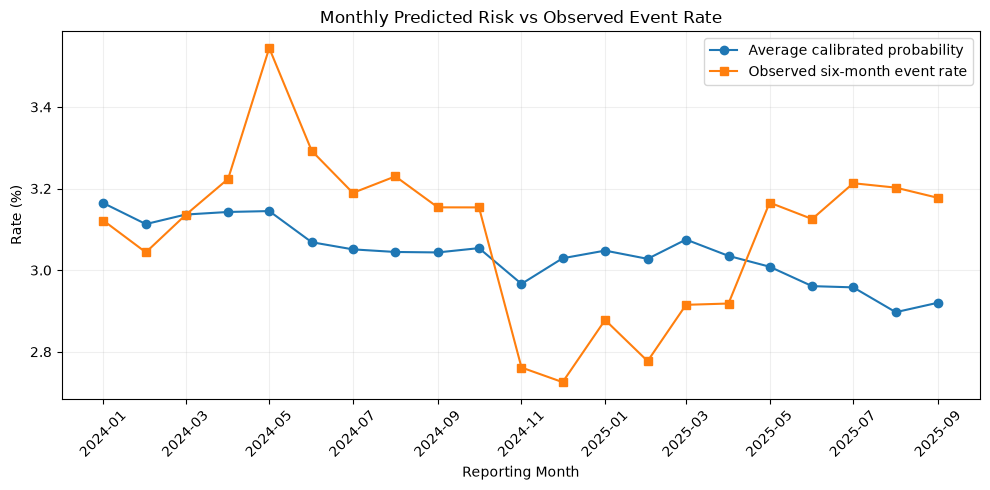

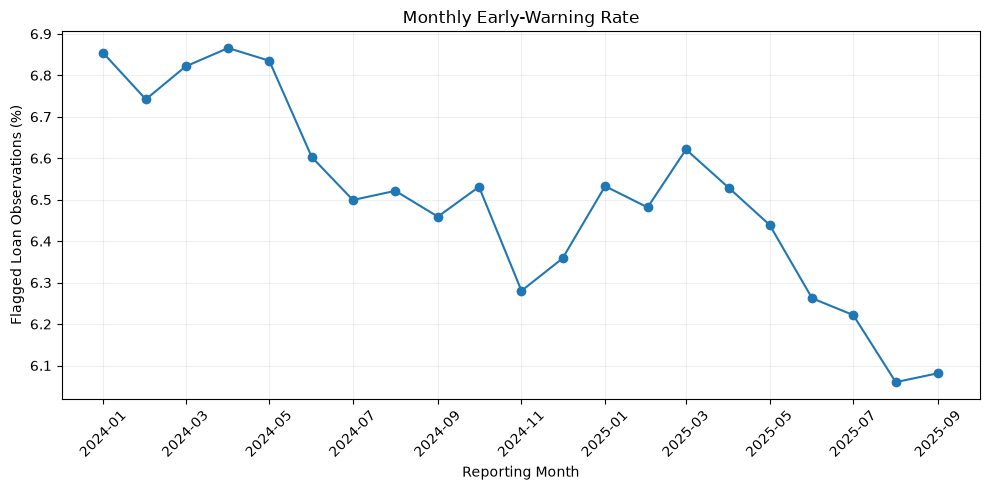

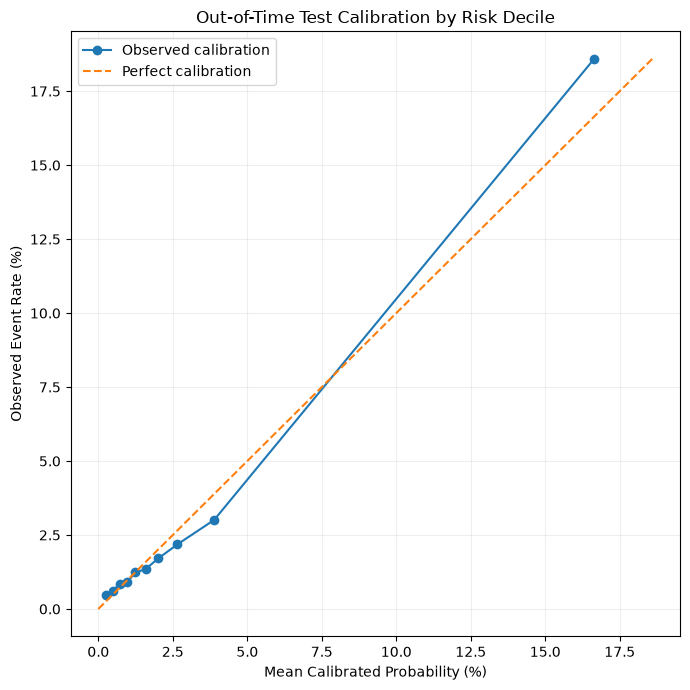

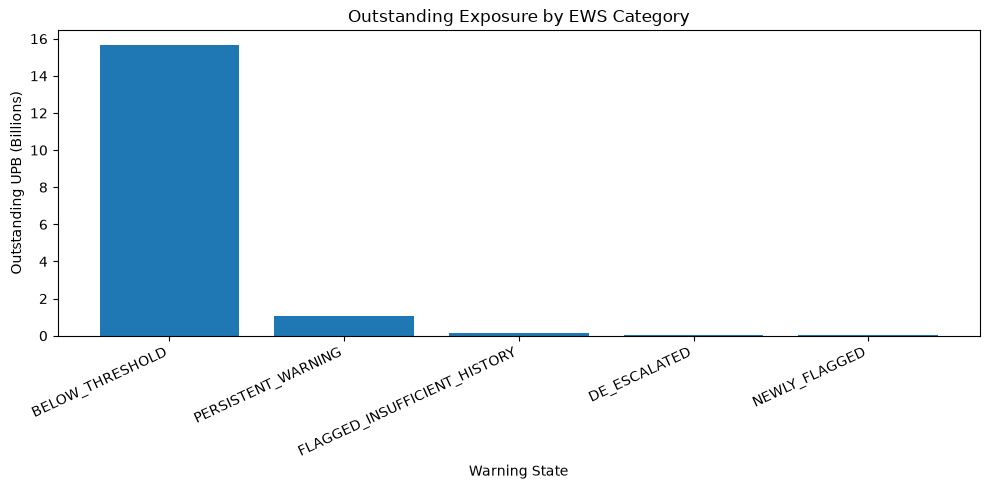

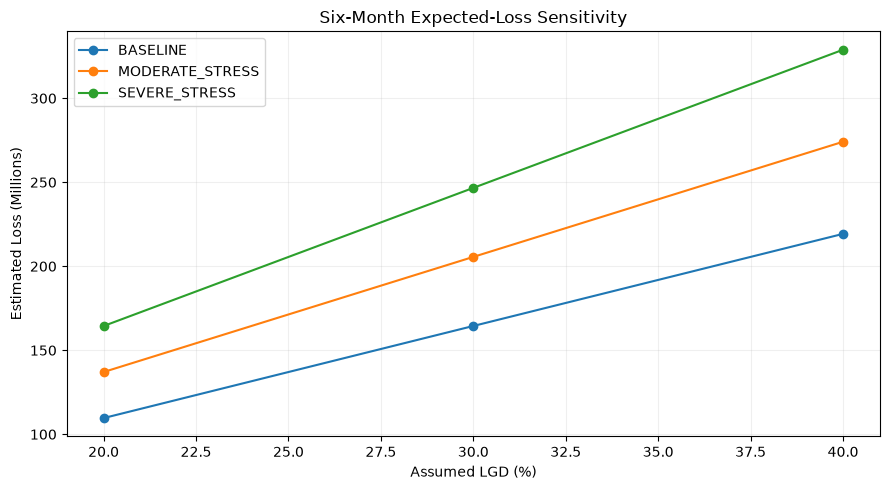


DASHBOARD CHARTS GENERATED
OUTPUT: C:\Users\madhu\OneDrive\Desktop\MTP - Dynamic Credit Risk Early Warning\figures\dashboard


In [5]:
# ============================================================
# DASHBOARD CHART GENERATION
# ============================================================

import matplotlib.pyplot as plt

# Load compact summary tables
ews_exposure = pd.read_csv(
    PORTFOLIO_DIR / "corrected_exposure_by_ews_state.csv"
)

stress_results = pd.read_csv(
    PORTFOLIO_DIR / "portfolio_stress_sensitivity.csv"
)

calibration_deciles = pd.read_csv(
    CALIBRATION_DIR / "test_calibration_deciles.csv"
)

# 1. Monthly calibrated probability vs observed event rate
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_dashboard["reporting_month"],
    monthly_dashboard["average_calibrated_probability"] * 100,
    marker="o",
    label="Average calibrated probability"
)

plt.plot(
    monthly_dashboard["reporting_month"],
    monthly_dashboard["observed_six_month_event_rate"] * 100,
    marker="s",
    label="Observed six-month event rate"
)

plt.title("Monthly Predicted Risk vs Observed Event Rate")
plt.xlabel("Reporting Month")
plt.ylabel("Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    DASHBOARD_FIGURES_DIR / "monthly_calibrated_risk.png",
    dpi=250
)
plt.show()


# 2. Monthly warning rate
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_dashboard["reporting_month"],
    monthly_dashboard["warning_rate"] * 100,
    marker="o"
)

plt.title("Monthly Early-Warning Rate")
plt.xlabel("Reporting Month")
plt.ylabel("Flagged Loan Observations (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    DASHBOARD_FIGURES_DIR / "monthly_warning_rate.png",
    dpi=250
)
plt.show()


# 3. Calibration by risk decile
plt.figure(figsize=(7, 7))

plt.plot(
    calibration_deciles["mean_calibrated_probability"] * 100,
    calibration_deciles["observed_event_rate"] * 100,
    marker="o",
    label="Observed calibration"
)

max_value = max(
    calibration_deciles["mean_calibrated_probability"].max(),
    calibration_deciles["observed_event_rate"].max()
) * 100

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Perfect calibration"
)

plt.title("Out-of-Time Test Calibration by Risk Decile")
plt.xlabel("Mean Calibrated Probability (%)")
plt.ylabel("Observed Event Rate (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    DASHBOARD_FIGURES_DIR / "test_calibration_deciles.png",
    dpi=250
)
plt.show()


# 4. Exposure by EWS category
plt.figure(figsize=(10, 5))

plt.bar(
    ews_exposure["corrected_ews_state"],
    ews_exposure["outstanding_upb"] / 1e9
)

plt.title("Outstanding Exposure by EWS Category")
plt.xlabel("Warning State")
plt.ylabel("Outstanding UPB (Billions)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    DASHBOARD_FIGURES_DIR / "ews_exposure_distribution.png",
    dpi=250
)
plt.show()


# 5. Stress sensitivity
plt.figure(figsize=(9, 5))

for scenario in stress_results["scenario"].unique():

    subset = stress_results[
        stress_results["scenario"] == scenario
    ].sort_values("lgd")

    plt.plot(
        subset["lgd"] * 100,
        subset["estimated_six_month_loss"] / 1e6,
        marker="o",
        label=scenario
    )

plt.title("Six-Month Expected-Loss Sensitivity")
plt.xlabel("Assumed LGD (%)")
plt.ylabel("Estimated Loss (Millions)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    DASHBOARD_FIGURES_DIR / "stress_sensitivity.png",
    dpi=250
)
plt.show()

print("\nDASHBOARD CHARTS GENERATED")
print("OUTPUT:", DASHBOARD_FIGURES_DIR)


## 4. Consolidated Dashboard Data Package

Create a compact folder containing the final dashboard-ready CSV summaries.

The original analytical files remain in their respective project folders. This package contains copies of selected aggregate outputs only.


In [6]:
# ============================================================
# CONSOLIDATE DASHBOARD DATA
# ============================================================

import shutil

dashboard_sources = {
    "monthly_risk.csv":
        DASHBOARD_DIR / "monthly_risk_dashboard.csv",

    "portfolio_exposure.csv":
        PORTFOLIO_DIR / "portfolio_exposure_summary.csv",

    "ews_exposure.csv":
        PORTFOLIO_DIR / "corrected_exposure_by_ews_state.csv",

    "geographic_concentration.csv":
        PORTFOLIO_DIR / "geographic_concentration.csv",

    "loan_purpose_concentration.csv":
        PORTFOLIO_DIR / "loan_purpose_concentration.csv",

    "ltv_concentration.csv":
        PORTFOLIO_DIR / "ltv_concentration.csv",

    "stress_sensitivity.csv":
        PORTFOLIO_DIR / "portfolio_stress_sensitivity.csv",

    "expected_loss_by_ews.csv":
        PORTFOLIO_DIR / "expected_loss_by_ews_state.csv",

    "test_calibration_metrics.csv":
        CALIBRATION_DIR / "test_calibration_metrics.csv",

    "test_calibration_deciles.csv":
        CALIBRATION_DIR / "test_calibration_deciles.csv",

    "ews_borrower_summary.csv":
        DYNAMIC_DIR / "borrower_ews_summary.csv"
}

copy_results = []

for destination_name, source_file in dashboard_sources.items():

    if source_file.exists():

        destination = DASHBOARD_DIR / destination_name

        shutil.copy2(source_file, destination)

        copy_results.append({
            "file": destination_name,
            "status": "COPIED",
            "size_kb": round(
                destination.stat().st_size / 1024, 2
            )
        })

    else:

        copy_results.append({
            "file": destination_name,
            "status": "SOURCE MISSING",
            "size_kb": None
        })

dashboard_inventory = pd.DataFrame(copy_results)

display(dashboard_inventory)

print(
    "\nSUCCESSFUL COPIES:",
    (dashboard_inventory["status"] == "COPIED").sum()
)

print(
    "MISSING SOURCES:",
    (dashboard_inventory["status"] != "COPIED").sum()
)

,file,status,size_kb
0,monthly_risk.csv,COPIED,2.49
1,portfolio_exposure.csv,COPIED,0.36
2,ews_exposure.csv,COPIED,0.72
3,geographic_concentration.csv,COPIED,4.88
4,loan_purpose_concentration.csv,COPIED,0.38
5,ltv_concentration.csv,COPIED,0.55
6,stress_sensitivity.csv,COPIED,1.45
7,expected_loss_by_ews.csv,COPIED,0.71
8,test_calibration_metrics.csv,COPIED,0.39
9,test_calibration_deciles.csv,COPIED,1.25



SUCCESSFUL COPIES: 11
MISSING SOURCES: 0


In [7]:
# ============================================================
# DASHBOARD PACKAGE AUDIT
# ============================================================

dashboard_csv_files = list(
    DASHBOARD_DIR.glob("*.csv")
)

audit_results = []

for file in dashboard_csv_files:

    try:
        df = pd.read_csv(file)

        audit_results.append({
            "file": file.name,
            "rows": len(df),
            "columns": len(df.columns),
            "empty": df.empty,
            "read_status": "PASS"
        })

    except Exception as error:

        audit_results.append({
            "file": file.name,
            "rows": None,
            "columns": None,
            "empty": None,
            "read_status": str(error)
        })

dashboard_audit = pd.DataFrame(audit_results)

display(dashboard_audit)

print(
    "\nALL CSV FILES READABLE:",
    (dashboard_audit["read_status"] == "PASS").all()
)

print(
    "DASHBOARD CSV COUNT:",
    len(dashboard_csv_files)
)

print(
    "DASHBOARD FIGURE COUNT:",
    len(list(DASHBOARD_FIGURES_DIR.glob("*.png")))
)

,file,rows,columns,empty,read_status
0,dashboard_source_inventory.csv,18,3,False,PASS
1,ews_borrower_summary.csv,1,8,False,PASS
2,ews_exposure.csv,5,7,False,PASS
3,expected_loss_by_ews.csv,5,7,False,PASS
4,geographic_concentration.csv,54,7,False,PASS
5,loan_purpose_concentration.csv,3,7,False,PASS
6,ltv_concentration.csv,5,7,False,PASS
7,monthly_risk.csv,21,8,False,PASS
8,monthly_risk_dashboard.csv,21,8,False,PASS
9,portfolio_exposure.csv,1,10,False,PASS



ALL CSV FILES READABLE: True
DASHBOARD CSV COUNT: 13
DASHBOARD FIGURE COUNT: 5
